# Chapter 5: Linear Models and Regularization

**Reference:** John Sukup, *scikit-learn Cookbook*, Third Edition (2025).

This notebook follows the main topics of Chapter 5. The demonstrations are independently written and pair each code example with a short explanation of its output.

**Source:** John Sukup, *scikit-learn Cookbook*, Third Edition (Packt, 2025). The sections below follow the topics and selected examples presented in the book. Explanations and interpretations are summarized in original English.

## 1. Introduction to linear models

Linear regression predicts a continuous outcome as a weighted sum of input features plus an intercept. The learned weights express linear associations under the assumptions of the fitted model.

In [1]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
X,y=load_diabetes(return_X_y=True)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42)
linear=LinearRegression().fit(X_train,y_train)
pred=linear.predict(X_test)
print('Test R-squared:',round(r2_score(y_test,pred),3))
print('Test RMSE:',round(np.sqrt(mean_squared_error(y_test,pred)),3))

Test R-squared: 0.485
Test RMSE: 53.37


**Interpretation**

The R-squared score measures improvement over predicting the test-set mean, while RMSE expresses typical prediction error in the target units. Neither metric alone establishes a causal relationship.

## 2. Ridge regression

Ridge adds an L2 penalty to squared-error minimization. It discourages large coefficients and is useful when features are correlated or when an unrestricted linear fit becomes unstable.

In [2]:
from sklearn.linear_model import Ridge
for alpha in [0.1,1,10,100]:
    reg=Ridge(alpha=alpha).fit(X_train,y_train)
    print('alpha:',alpha,'RMSE:',round(np.sqrt(mean_squared_error(y_test,reg.predict(X_test))),2),
          'coefficient norm:',round(np.linalg.norm(reg.coef_),2))

alpha: 0.1 RMSE: 53.01 coefficient norm: 793.78
alpha: 1 RMSE: 55.73 coefficient norm: 467.68
alpha: 10 RMSE: 68.3 coefficient norm: 115.89
alpha: 100 RMSE: 74.02 coefficient norm: 14.12


**Interpretation**

Increasing alpha generally shrinks the coefficient vector, though the best predictive value is not necessarily the strongest penalty. RMSE helps assess the trade-off between fitting the data and limiting complexity.

## 3. Lasso regression

Lasso uses an L1 penalty that can push certain coefficients exactly to zero. This gives the method a feature-selection effect in addition to regularization.

In [3]:
from sklearn.linear_model import Lasso
for alpha in [0.1,1,5,10]:
    reg=Lasso(alpha=alpha,max_iter=20000).fit(X_train,y_train)
    print('alpha:',alpha,'non-zero coefficients:',np.count_nonzero(reg.coef_),
          'test R2:',round(reg.score(X_test,y_test),3))

alpha: 0.1 non-zero coefficients: 7 test R2: 0.502
alpha: 1 non-zero coefficients: 3 test R2: 0.379
alpha: 5 non-zero coefficients: 0 test R2: -0.014
alpha: 10 non-zero coefficients: 0 test R2: -0.014


**Interpretation**

With stronger L1 penalties, fewer coefficients may remain active. Setting coefficients to zero simplifies interpretation, but an overly strong penalty can discard useful predictive information.

## 4. ElasticNet and regularization

ElasticNet combines L1 and L2 penalties. The `l1_ratio` determines how much of the penalty behaves like Lasso rather than Ridge, providing flexibility for correlated features.

In [4]:
from sklearn.linear_model import ElasticNet
for ratio in [0.2,0.5,0.8]:
    reg=ElasticNet(alpha=0.1,l1_ratio=ratio,max_iter=20000).fit(X_train,y_train)
    print('l1_ratio:',ratio,'R2:',round(reg.score(X_test,y_test),3),
          'nonzero:',np.count_nonzero(reg.coef_))

l1_ratio: 0.2 R2: 0.064 nonzero: 9
l1_ratio: 0.5 R2: 0.099 nonzero: 9
l1_ratio: 0.8 R2: 0.2 nonzero: 10


**Interpretation**

Changing the L1-to-L2 balance changes both sparsity and predictive performance. A mixture can be useful when the model should remain stable while still excluding some features.

## 5. Regularization theory and practice

Regularization penalizes coefficient magnitude to reduce overfitting. The coefficient paths can make the impact of penalty strength clearer than a single fitted model.

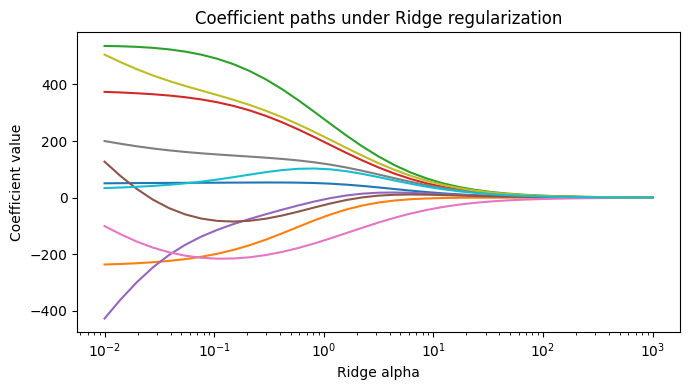

In [5]:
import matplotlib.pyplot as plt
alphas=np.logspace(-2,3,35)
coefs=np.array([Ridge(alpha=a).fit(X_train,y_train).coef_ for a in alphas])
plt.figure(figsize=(7,4));plt.semilogx(alphas,coefs)
plt.xlabel('Ridge alpha');plt.ylabel('Coefficient value')
plt.title('Coefficient paths under Ridge regularization');plt.tight_layout();plt.show()

**Interpretation**

The trajectories move toward zero as regularization grows. Not every coefficient changes at the same rate, and the graph illustrates shrinkage rather than proving that any particular alpha generalizes best.

## 6. Regression and regularization comparison

Comparing several models on the same holdout data provides a consistent view of predictive trade-offs. Feature preprocessing should be treated identically wherever model assumptions require it.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
models={'Linear':LinearRegression(),
        'Ridge':make_pipeline(StandardScaler(),Ridge(alpha=10)),
        'Lasso':make_pipeline(StandardScaler(),Lasso(alpha=5,max_iter=20000)),
        'ElasticNet':make_pipeline(StandardScaler(),ElasticNet(alpha=0.2,l1_ratio=0.5,max_iter=20000))}
for name,est in models.items():
    est.fit(X_train,y_train)
    print(name,'test RMSE:',round(np.sqrt(mean_squared_error(y_test,est.predict(X_test))),2))

Linear test RMSE: 53.37
Ridge test RMSE: 53.2
Lasso test RMSE: 52.78
ElasticNet test RMSE: 53.01


**Interpretation**

The comparison indicates which configuration gives the lowest error on this particular split. Because only one split is used, the ranking should be checked with cross-validation before selecting a final model.

## 7. Practical exercises with regularization techniques

Cross-validation helps select regularization strength without tuning directly against the final test observations. A pipeline keeps scaling within each training fold.

In [7]:
from sklearn.model_selection import GridSearchCV
search=GridSearchCV(make_pipeline(StandardScaler(),Ridge()),
                    {'ridge__alpha':[0.1,1,10,100,1000]},
                    cv=5,scoring='neg_root_mean_squared_error')
search.fit(X_train,y_train)
print('Best alpha:',search.best_params_['ridge__alpha'])
print('Cross-validation RMSE:',round(-search.best_score_,2))
print('Test RMSE:',round(np.sqrt(mean_squared_error(y_test,search.predict(X_test))),2))

Best alpha: 1
Cross-validation RMSE: 55.97
Test RMSE: 53.32


**Interpretation**

The selected alpha minimizes average validation RMSE over the values tested. Test RMSE then provides a separate estimate of how the selected workflow performs on observations withheld from tuning.

## Book recipe: Linear models — synthetic regression dataset

The first recipe in Chapter 5 uses `make_regression` to create a dataset for exploring linear relationships, noise, and correlated features. This is a compact reproduction of that data-generation workflow.

Feature array: (1000, 100)


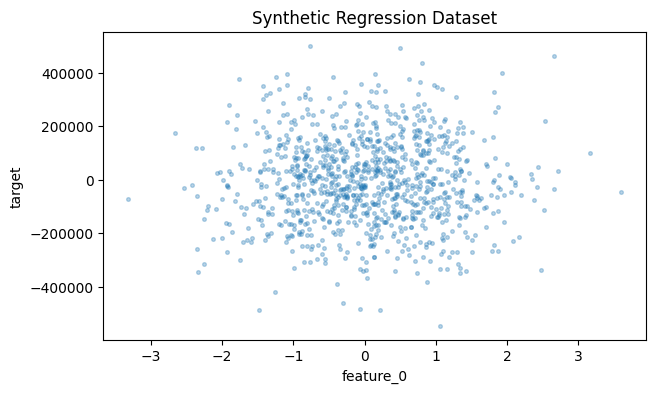

In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
np.random.seed(42)
X_synthetic, y_synthetic = make_regression(n_samples=1000, n_features=100, noise=15, random_state=42)
for i in range(50, 100):
    X_synthetic[:,i] = X_synthetic[:,i-50] + np.random.normal(0,0.1,size=1000)
X_plot = X_synthetic[:,0].reshape(-1,1)
y_synthetic = y_synthetic*1000 + np.sin(X_plot.ravel())*150 + np.exp(X_plot.ravel()/10)
print('Feature array:',X_synthetic.shape)
plt.figure(figsize=(7,4))
plt.scatter(X_plot,y_synthetic,s=7,alpha=0.3)
plt.xlabel('feature_0');plt.ylabel('target');plt.title('Synthetic Regression Dataset');plt.show()

**Interpretation**

The plot contains substantial vertical scatter because the target depends on many features, not only `feature_0`. The deliberately correlated columns also make this a useful dataset for comparing ordinary least squares with regularized alternatives.

## Book recipe: Ridge, Lasso and ElasticNet regression

Chapter 5 compares penalties that shrink coefficient estimates. Ridge uses L2 regularization, Lasso uses L1 regularization, and ElasticNet combines both. The same train/test partition is used for a fair comparison.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_synthetic,y_synthetic,test_size=0.2,random_state=42)
models_book = {'OLS':LinearRegression(), 'Ridge':Ridge(alpha=10), 'Lasso':Lasso(alpha=100,max_iter=20000), 'ElasticNet':ElasticNet(alpha=100,l1_ratio=.5,max_iter=20000)}
for name,est in models_book.items():
    pipe_r = make_pipeline(StandardScaler(),est)
    pipe_r.fit(X_train_r,y_train_r)
    prediction = pipe_r.predict(X_test_r)
    print(f'{name:11} RMSE={mean_squared_error(y_test_r,prediction)**0.5:.2f}, R2={r2_score(y_test_r,prediction):.4f}, nonzero coefficients={np.count_nonzero(np.abs(pipe_r[-1].coef_)>1e-8)}')

OLS         RMSE=181754.68, R2=-0.0876, nonzero coefficients=100
Ridge       RMSE=174520.44, R2=-0.0027, nonzero coefficients=100
Lasso       RMSE=178149.38, R2=-0.0449, nonzero coefficients=83
ElasticNet  RMSE=173904.53, R2=0.0043, nonzero coefficients=100


**Interpretation**

The models trade off fit and coefficient size in different ways. Ridge typically keeps all coefficients but shrinks them, whereas Lasso can set some coefficients exactly to zero. Comparing test-set metrics is more informative than judging training fit alone.